Train images: (60000, 28, 28) | Train labels: (60000,)
Test images : (10000, 28, 28) | Test labels : (10000,)


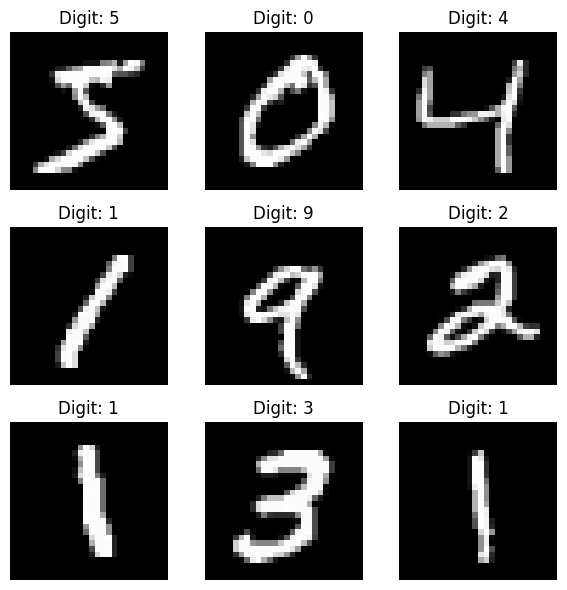

Preprocessed train shape: (60000, 28, 28, 1)
Preprocessed test shape : (10000, 28, 28, 1)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 10816)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │     2,769,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,772,362 (10.58 MB)

 Trainable params: 2,772,362 (10.58 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 64s 136ms/step - accuracy: 0.7969 - loss: 0.8938 - val_accuracy: 0.9034 - val_loss: 0.3568
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 64s 137ms/step - accuracy: 0.9044 - loss: 0.3339 - val_accuracy: 0.9197 - val_loss: 0.2855
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 82s 137ms/step - accuracy: 0.9189 - loss: 0.2794 - val_accuracy: 0.9303 - val_loss: 0.2493
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 62s 133ms/step - accuracy: 0.9291 - loss: 0.2447 - val_accuracy: 0.9351 - val_loss: 0.2227
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 65s 138ms/step - accuracy: 0.9369 - loss: 0.2183 - val_accuracy: 0.9438 - val_loss: 0.1959
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9438 - loss: 0.1959
Test Loss: 0.1959
Test Accuracy: 0.9438


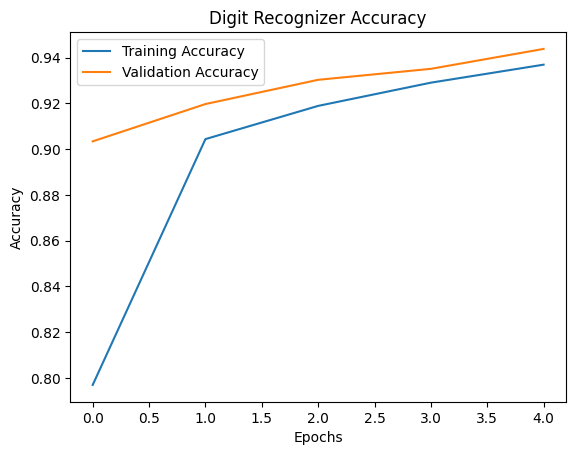

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step
Image 1: Predicted = 7, Actual = 7
Image 2: Predicted = 2, Actual = 2
Image 3: Predicted = 1, Actual = 1
Image 4: Predicted = 0, Actual = 0
Image 5: Predicted = 4, Actual = 4
Image 6: Predicted = 1, Actual = 1
Image 7: Predicted = 4, Actual = 4
Image 8: Predicted = 9, Actual = 9
Image 9: Predicted = 6, Actual = 5
Image 10: Predicted = 9, Actual = 9


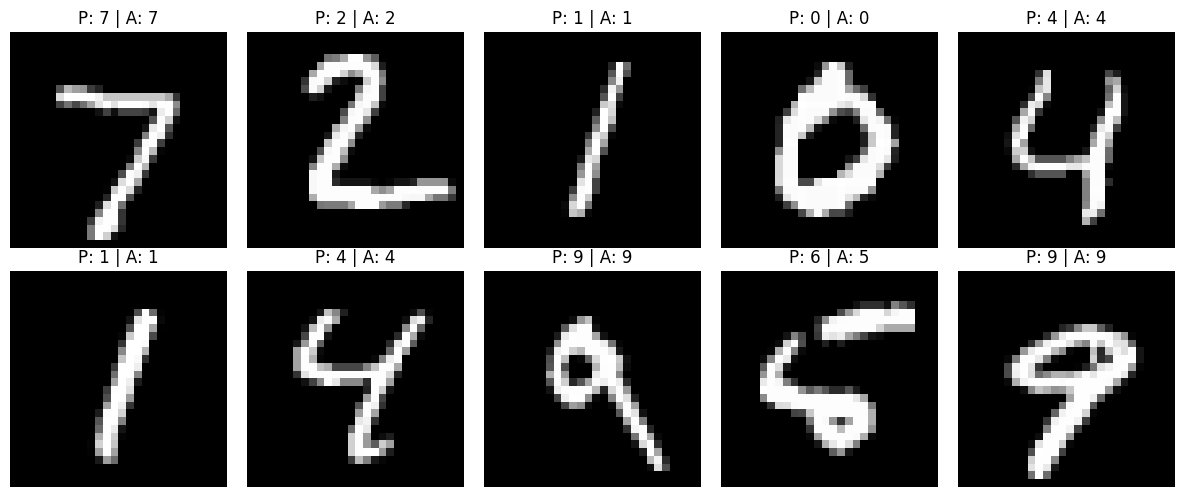

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from keras.datasets import mnist
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import SGD
# Step 1: Load the MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()
print("Train images:", x_train.shape, "| Train labels:", y_train.shape)
print("Test images :", x_test.shape, "| Test labels :", y_test.shape)
# Step 2: View sample digits before preprocessing
plt.figure(figsize=(6, 6))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title("Digit: " + str(y_train[i]))
    plt.axis("off")
plt.tight_layout()
plt.show()
# Step 3: Reshape and normalize image data
x_train = x_train.reshape(-1, 28, 28, 1).astype("float32") / 255
x_test = x_test.reshape(-1, 28, 28, 1).astype("float32") / 255
# Step 4: Convert labels into one-hot encoded categories
num_classes = 10
y_train = to_categorical(y_train, num_classes)
y_test = to_categorical(y_test, num_classes)
print("Preprocessed train shape:", x_train.shape)
print("Preprocessed test shape :", x_test.shape)
# Step 5: Build the CNN model
model = Sequential([
    Conv2D(64, (3, 3), activation="relu", input_shape=(28, 28, 1)),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(256, activation="relu"),
    Dense(num_classes, activation="softmax")
])
# Step 6: Compile and train the model
model.compile(
    loss="categorical_crossentropy",
    optimizer=SGD(learning_rate=0.01),
    metrics=["accuracy"]
)
model.summary()
history = model.fit(
    x_train, y_train,
    batch_size=128,
    epochs=5,
    validation_data=(x_test, y_test)
)
# Step 7: Evaluate model performance
test_loss, test_accuracy = model.evaluate(x_test, y_test)
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 4))
# Step 8: Plot training and validation accuracy
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Digit Recognizer Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()
# Step 9: Predict and display test images
predictions = model.predict(x_test)
plt.figure(figsize=(12, 5))
for i in range(10):
    pred = np.argmax(predictions[i])
    actual = np.argmax(y_test[i])
    print(f"Image {i + 1}: Predicted = {pred}, Actual = {actual}")
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.title(f"P: {pred} | A: {actual}")
    plt.axis("off")
plt.tight_layout()
plt.show()